# 04 Numbers for the "Description of the data" section

This notebook collects everything the data section of the report needs: where the data come from,
how many rows survive each cleaning step, what the outcome and the lake covariates look like, and how
the records are spread over time and space.

Every number is also written to `results/data_description.txt`. Paste that file's content back to
get the section written. Tables are saved as LaTeX in `results/tables/` and figures in `figures/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import icebreak_common as ic

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
TAB_DIR = ic.RES_DIR / "tables"
TAB_DIR.mkdir(exist_ok=True)

out_lines = []

def note(key, value):
    """Print a number and store it for data_description.txt."""
    line = f"{key}: {value}"
    print(line)
    out_lines.append(line)

def section(title):
    print(f"\n=== {title} ===")
    out_lines.append(f"\n=== {title} ===")

def save_table(df, name, caption, index=True, float_fmt="{:.1f}"):
    """Store a table as plain text (for pasting) and as a simple LaTeX tabular."""
    out_lines.append(f"\n[table: {name}] {caption}")
    out_lines.append(df.to_string(index=index))
    cols = ([df.index.name or ""] if index else []) + [str(c) for c in df.columns]
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "" if np.isnan(v) else float_fmt.format(v)
        return str(v)
    rows = []
    for idx, r in df.iterrows():
        cells = ([str(idx)] if index else []) + [fmt(v) for v in r.values]
        rows.append(" & ".join(c.replace("_", r"\_").replace("%", r"\%") for c in cells) + r" \\")
    tex = "\n".join([
        r"\begin{table}[ht]", r"\centering", f"\\caption{{{caption}}}", f"\\label{{tab:{name}}}",
        r"\begin{tabular}{" + "l" + "r" * (len(cols) - 1) + "}", r"\hline",
        " & ".join(c.replace("_", r"\_").replace("%", r"\%") for c in cols) + r" \\", r"\hline",
        *rows, r"\hline", r"\end{tabular}", r"\end{table}"])
    (TAB_DIR / f"{name}.tex").write_text(tex, encoding="utf-8")
    try:
        display(df)          # in Jupyter
    except NameError:
        print(df.to_string())

raw = pd.read_csv(ic.DATA_FILE)
places = pd.read_csv(ic.PLACES_FILE)

## 1. Source and size of the raw file
One row is one site in one ice season. A season is named after the spring in which the ice breaks up.

In [2]:
section("Raw data")
note("Rows (site x season)", f"{len(raw):,}")
note("Observation sites", raw.Paikka_Id.nunique())
note("Distinct lakes (Jarvi_Id, sites with a lake match)", raw.Jarvi_Id.nunique())
note("Sites without a lake match", raw[raw.Jarvi_Id.isna()].Paikka_Id.nunique())
note("Seasons covered", f"{raw.season.min()}-{raw.season.max()}")
note("Main drainage basins (PaaVesalNimi)", raw.PaaVesalNimi.nunique())
note("Municipalities (KuntaNimi)", raw.KuntaNimi.nunique())
note("Sites sharing a lake with another site",
     f"{(places.n_sites_on_lake > 1).sum()} sites on {places[places.n_sites_on_lake > 1].Jarvi_Id.nunique()} lakes")


=== Raw data ===
Rows (site x season): 9,346
Observation sites: 105
Distinct lakes (Jarvi_Id, sites with a lake match): 94
Sites without a lake match: 2
Seasons covered: 1900-2026
Main drainage basins (PaaVesalNimi): 20
Municipalities (KuntaNimi): 77
Sites sharing a lake with another site: 16 sites on 7 lakes


## 2. Observations per variable
How many site-seasons have each ice date. Code 28 (break-up of the ice cover) is the outcome; code 27
(ice leaving the open lake beyond the observer's view, renamed `breakup_offshore`) and freeze-up are
secondary.

In [3]:
section("Available observations per variable")
avail = pd.DataFrame({
    "non-missing": [raw[c].notna().sum() for c in
                    ["breakup_doy", "breakup_offshore_doy", "freeze_day_from_sep1",
                     "freeze_first_day_from_sep1", "ice_duration"]],
}, index=["break-up (code 28)", "offshore break-up (code 27)", "freeze-up",
          "first freeze-up", "ice duration"])
avail["share of rows (%)"] = 100 * avail["non-missing"] / len(raw)
save_table(avail, "availability", "Number of site-seasons with each ice date in the raw file.")

note("Seasons with several break-up records (first kept)", int(raw.multiple_breakups.sum()))
note("Seasons with several freeze-up records", int(raw.multiple_freezes.sum()))
both = raw.breakup_doy.notna() & raw.breakup_offshore_doy.notna()
note("Seasons with both code 27 and code 28", int(both.sum()))
note("  of which code 27 is later than code 28",
     int((raw.loc[both, "breakup_offshore_doy"] > raw.loc[both, "breakup_doy"]).sum()))


=== Available observations per variable ===


,non-missing,share of rows (%)
break-up (code 28),9021,96.522577
offshore break-up (code 27),1189,12.722020
freeze-up,7830,83.779157
first freeze-up,5747,61.491547
ice duration,7569,80.986518


Seasons with several break-up records (first kept): 57
Seasons with several freeze-up records: 29
Seasons with both code 27 and code 28: 1178
  of which code 27 is later than code 28: 705


## 3. From the raw file to the modelling data
The number of rows and sites left after each filter.

In [4]:
section("Filtering steps")
steps = []
cur = raw.copy()
steps.append(("Raw file", len(cur), cur.Paikka_Id.nunique()))
cur = cur[cur.breakup_doy.notna()]
steps.append(("With a break-up date (code 28)", len(cur), cur.Paikka_Id.nunique()))
n_susp = int(raw.breakup_suspicious.sum())
n_susp_with_date = int((raw.breakup_suspicious & raw.breakup_doy.notna()).sum())
cur = cur[~cur.breakup_suspicious]
if n_susp_with_date:
    steps.append(("Suspicious dates removed", len(cur), cur.Paikka_Id.nunique()))
cur = cur[cur.reaches_recent]
steps.append(("Sites whose record reaches 2015 or later", len(cur), cur.Paikka_Id.nunique()))
flow = pd.DataFrame(steps, columns=["step", "rows", "sites"]).set_index("step")
save_table(flow, "filtering", "Rows and sites left after each filtering step.", float_fmt="{:.0f}")
note("Flagged suspicious break-up dates", n_susp)
susp = raw[raw.breakup_suspicious][["Nimi", "season", "lat"]]
note("  which", "; ".join(f"{r.Nimi} {r.season} ({r.lat:.1f} N)" for r in susp.itertuples()))
note("  still has a date in the cleaned file", "yes" if n_susp_with_date else "no (set to missing during cleaning)")

d = ic.load_breakup(recent_only=True)
d_all = ic.load_breakup(recent_only=False)
assert len(d) == flow["rows"].iloc[-1]


=== Filtering steps ===


,rows,sites
step,,
Raw file,9346,105
With a break-up date (code 28),9021,105
Sites whose record reaches 2015 or later,6093,64


Flagged suspicious break-up dates: 1
  which: Hyrynjärvi, Hyrynsalmi 1990 (64.6 N)
  still has a date in the cleaned file: no (set to missing during cleaning)


## 4. The outcome: break-up day of year (main subset)

In [5]:
section("Outcome: break-up day of year (main subset)")
y = d[ic.RESPONSE]
desc = y.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
for k, v in desc.items():
    note(f"breakup_doy {k}", f"{v:.1f}")
doy_to_date = lambda x: (pd.Timestamp("2001-01-01") + pd.Timedelta(days=float(x) - 1)).strftime("%d %b")
note("Median as a date (non-leap year)", doy_to_date(y.median()))
note("Earliest", "; ".join(f"{r.Nimi} {r.breakup_date}" for r in d.nsmallest(3, ic.RESPONSE).itertuples()))
note("Latest", "; ".join(f"{r.Nimi} {r.breakup_date}" for r in d.nlargest(3, ic.RESPONSE).itertuples()))

by_region = d.groupby("region").agg(
    sites=("site", "nunique"), rows=("site", "size"),
    lat_min=("lat", "min"), lat_max=("lat", "max"),
    mean_doy=(ic.RESPONSE, "mean"), sd_doy=(ic.RESPONSE, "std"),
    earliest=(ic.RESPONSE, "min"), latest=(ic.RESPONSE, "max")).reindex(ic.REGION_LABELS)
save_table(by_region, "regions", "Break-up day of year by region in the main subset "
           "(south < 62.5 N <= central < 65 N <= north).")

per = pd.DataFrame({
    "all 105 sites": [d_all[d_all.season.between(a, b)][ic.RESPONSE].mean()
                      for a, b in [(1900, 1930), (1931, 1960), (1961, 1990), (1991, 2026)]],
    "main subset": [d[d.season.between(a, b)][ic.RESPONSE].mean()
                    for a, b in [(1900, 1930), (1931, 1960), (1961, 1990), (1991, 2026)]],
}, index=["1900-1930", "1931-1960", "1961-1990", "1991-2026"])
per.index.name = "period"
save_table(per, "periods", "Mean break-up day of year by 30-year period.")


=== Outcome: break-up day of year (main subset) ===
breakup_doy count: 6093.0
breakup_doy mean: 131.3
breakup_doy std: 13.2
breakup_doy min: 73.0
breakup_doy 5%: 112.0
breakup_doy 25%: 123.0
breakup_doy 50%: 130.0
breakup_doy 75%: 138.0
breakup_doy 95%: 155.0
breakup_doy max: 181.0
Median as a date (non-leap year): 10 May
Earliest: Kuivajärvi, Saari 2020-03-13; Saimaa, Lauritsala 2020-03-19; Pyhäjärvi, Kauttua 2020-03-20
Latest: Kilpisjärvi 1958-06-30; Kilpisjärvi 1998-06-30; Inari, selkävedet 1996-06-29


,sites,rows,lat_min,lat_max,mean_doy,sd_doy,earliest,latest
region,,,,,,,,
south,25,2530,60.416389,62.255000,123.897628,10.098536,73.0,154.0
central,27,2733,62.616111,64.882778,132.245884,9.200404,96.0,162.0
north,12,830,65.103333,69.755833,150.628916,12.253342,109.0,181.0


,all 105 sites,main subset
period,,
1900-1930,130.488486,132.465063
1931-1960,130.776913,132.294636
1961-1990,132.412237,134.137001
1991-2026,127.570490,127.444389


## 5. Record lengths and coverage over time

In [6]:
section("Record lengths and coverage")
rec = d.groupby("site").agg(first=("season", "min"), last=("season", "max"),
                            n=("season", "size"), lat=("lat", "first"))
rec["span"] = rec["last"] - rec["first"] + 1
rec["completeness"] = rec["n"] / rec["span"]
note("Years of data per site (min / median / max)",
     f"{rec.n.min()} / {rec.n.median():.0f} / {rec.n.max()}")
note("First year of record (min / median / max)",
     f"{rec['first'].min()} / {rec['first'].median():.0f} / {rec['first'].max()}")
note("Sites starting by 1915", int((rec["first"] <= 1915).sum()))
note("Median completeness within a site's span", f"{100 * rec.completeness.median():.0f} %")
cnt = d.groupby("season").site.nunique()
cnt_all = d_all.groupby("season").site.nunique()
note("Sites reporting per season, main subset (min / median / max)",
     f"{cnt.min()} / {cnt.median():.0f} / {cnt.max()}")
note("Peak number of reporting sites, all 105 sites", f"{cnt_all.max()} (in {cnt_all.idxmax()})")
note("Sites reporting in 2025, all sites", int(cnt_all.get(2025, 0)))
note("Sites reporting in 2026 (spring 2026)", int(cnt.get(2026, 0)))
note("Closed sites (record ends before 2015)",
     d_all.site.nunique() - d.site.nunique())


=== Record lengths and coverage ===
Years of data per site (min / median / max): 51 / 102 / 127
First year of record (min / median / max): 1900 / 1912 / 1971
Sites starting by 1915: 40
Median completeness within a site's span: 98 %
Sites reporting per season, main subset (min / median / max): 12 / 49 / 64
Peak number of reporting sites, all 105 sites: 103 (in 1971)
Sites reporting in 2025, all sites: 47
Sites reporting in 2026 (spring 2026): 36
Closed sites (record ends before 2015): 41


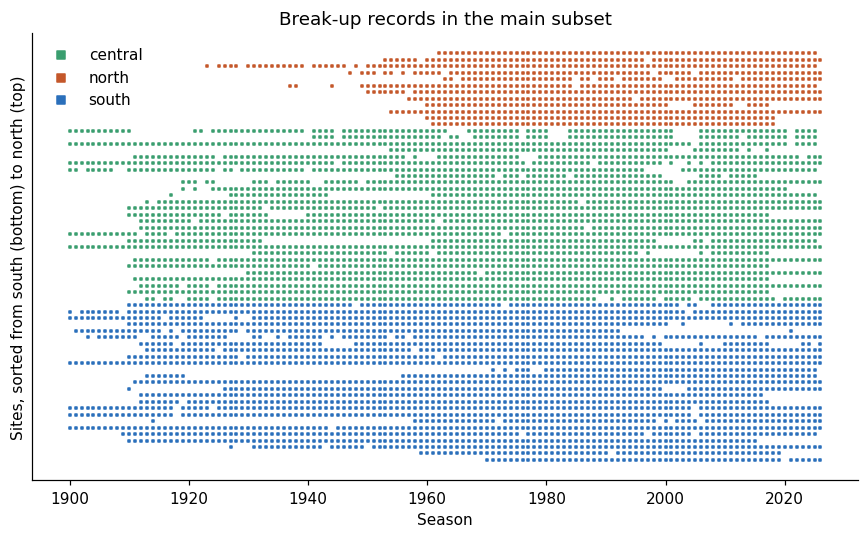

In [7]:
order = rec.sort_values("lat").index
pos = {s: i for i, s in enumerate(order)}
reg_col = {"south": "#2a6fbb", "central": "#3a9e6f", "north": "#c4572a"}
fig, ax = plt.subplots(figsize=(8, 5))
for reg, g in d.groupby("region"):
    ax.scatter(g.season, g.site.map(pos), s=2, marker="s", color=reg_col[reg], label=reg)
ax.set_yticks([])
ax.set_ylabel("Sites, sorted from south (bottom) to north (top)")
ax.set_xlabel("Season")
ax.legend(frameon=False, markerscale=4, loc="upper left")
ax.set_title("Break-up records in the main subset")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig_data_coverage.png", bbox_inches="tight")
plt.show()

## 6. Lake covariates (one row per site, main subset)

In [8]:
section("Site and lake covariates (main subset, one row per site)")
site = d.groupby("site").first()
cov = pd.DataFrame({
    "latitude (deg N)": site.lat, "longitude (deg E)": site.lon,
    "altitude (m)": site.lake_altitude_m, "area (km2)": site.lake_area_km2,
    "mean depth (m)": site.lake_mean_depth_m, "max depth (m)": site.lake_max_depth_m,
})
cov_tab = cov.describe().T[["count", "min", "50%", "max"]].rename(columns={"50%": "median"})
cov_tab.index.name = "covariate"
save_table(cov_tab, "covariates", "Site and lake covariates for the 64 sites of the main analysis.",
           float_fmt="{:.2f}")
note("Sites with uncertain lake match (lake_info_uncertain)", int(site.lake_info_uncertain.sum()))
note("Sites with missing lake area", int(site.lake_area_km2.isna().sum()))
note("Sites with missing mean depth", int(site.lake_mean_depth_m.isna().sum()))
note("Correlation latitude-altitude (sites)", f"{cov['latitude (deg N)'].corr(cov['altitude (m)']):.2f}")
note("Correlation latitude-longitude (sites)", f"{cov['latitude (deg N)'].corr(cov['longitude (deg E)']):.2f}")
note("Correlation latitude-log area (sites)", f"{site.lat.corr(site.log_lake_area):.2f}")
note("Sites sharing a lake (main subset)", int((site.n_sites_on_lake > 1).sum()))


=== Site and lake covariates (main subset, one row per site) ===


,count,min,median,max
covariate,,,,
latitude (deg N),64.0,60.416389,62.854722,69.755833
longitude (deg E),64.0,20.792778,25.839722,29.554167
altitude (m),64.0,38.060000,99.125000,473.160000
area (km2),62.0,1.019730,50.843350,1377.030000
mean depth (m),56.0,1.111490,6.685000,19.500000
max depth (m),58.0,2.420000,35.665000,92.000000


Sites with uncertain lake match (lake_info_uncertain): 7
Sites with missing lake area: 2
Sites with missing mean depth: 8
Correlation latitude-altitude (sites): 0.65
Correlation latitude-longitude (sites): 0.09
Correlation latitude-log area (sites): -0.18
Sites sharing a lake (main subset): 11


## 7. Secondary outcomes (main subset)

In [9]:
section("Secondary outcomes (main subset)")
for col, lab in [("freeze_day_from_sep1", "freeze-up, days from 1 Sep"),
                 ("ice_duration", "ice duration, days")]:
    x = d[col].dropna()
    note(lab, f"n = {len(x):,}, mean = {x.mean():.1f}, SD = {x.std():.1f}, "
              f"range {x.min():.0f}-{x.max():.0f}")


=== Secondary outcomes (main subset) ===
freeze-up, days from 1 Sep: n = 5,727, mean = 85.5, SD = 20.4, range 33-189
ice duration, days: n = 5,727, mean = 167.9, SD = 29.2, range 16-264


## 8. Quick facts for the text
Simple non-Bayesian numbers that motivate the models (the models give the final estimates).

In [10]:
section("Quick descriptive facts")
s_means = d.groupby("site").agg(lat=("lat", "first"), m=(ic.RESPONSE, "mean"))
b = np.polyfit(s_means.lat, s_means.m, 1)[0]
note("OLS slope of site mean break-up on latitude (days per degree)", f"{b:.1f}")
yr_sd = d.groupby("season")[ic.RESPONSE].mean().std()
note("SD of the yearly mean break-up over sites (days)", f"{yr_sd:.1f}")
note("Mean within-site SD (days)", f"{d.groupby('site')[ic.RESPONSE].std().mean():.1f}")
warm = d[d.season == 2020]
note("2020 (warm winter): mean break-up in the south",
     f"{warm[warm.region == 'south'][ic.RESPONSE].mean():.1f} "
     f"vs. long-term {d[d.region == 'south'][ic.RESPONSE].mean():.1f}")


=== Quick descriptive facts ===
OLS slope of site mean break-up on latitude (days per degree): 4.4
SD of the yearly mean break-up over sites (days): 7.9
Mean within-site SD (days): 8.7
2020 (warm winter): mean break-up in the south: 98.0 vs. long-term 123.9


## 9. Save everything

In [11]:
txt = "\n".join(out_lines)
(ic.RES_DIR / "data_description.txt").write_text(txt, encoding="utf-8")
print(f"Saved results/data_description.txt ({len(out_lines)} lines) and "
      f"{len(list(TAB_DIR.glob('*.tex')))} LaTeX tables in results/tables/")

Saved results/data_description.txt (68 lines) and 5 LaTeX tables in results/tables/
